# V1LD : convergence B&B exact vs LP-relax pour $\zeta_i$

**Objectif** : comparer deux façons de résoudre le sous-problème $\zeta_i$ dans V1LD.

| Variante | Solveur $\zeta_i$ | Propriété |
|----------|------------------|-----------|
| **V1LD-BnB** | B&B exact multi-dim | $\zeta_i^{\text{BnB}} \leq \zeta_i^{\text{LP}}$ → borne serrée |
| **V1LD-LP**  | LP fractionnaire 1D (min sur $j$) | sur-estime $\zeta_i$ → borne plus lâche, mais rapide |

**Instance** : `mknap1_4` (n=20, m=10), Song S=100, $\varepsilon=0.1$, $T=300$ itérations.

In [1]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt

ROOT = os.path.abspath('.')
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import v1ld_generic_cpp as cpp

def load_song(filepath, replication=0):
    rows = []
    with open(filepath) as f:
        for line in f:
            v = list(map(float, line.strip().split(',')))
            if int(v[4]) != replication:
                continue
            m, n = int(v[2]), int(v[3])
            A = np.array(v[5 : 5+m*n]).reshape(m, n)
            b = np.array(v[5+m*n : 5+m*n+m])
            c = np.array(v[5+m*n+m : 5+m*n+m+n])
            rows.append((A, b, c))
    N = len(rows)
    return rows[0][2], np.ones(N)/N, np.stack([r[0] for r in rows]), np.stack([r[1] for r in rows])

EPSILON = 0.10
T       = 300
N_REPS  = 5

INSTANCES = {
    'mknap1_4 (n=20, m=10)': 'data/knapsack/datasets-song/ccmk-song-mknap1_4-S100.txt',
}

VARIANTS = [
    ('V1LD-BnB', cpp.MKPProblemBnB, '#2166ac', '-'),
    ('V1LD-LP',  cpp.MKPProblemLP,  '#d6604d', '--'),
]

print('Instances :')
for lbl, path in INSTANCES.items():
    c,p,A,b = load_song(path)
    print(f'  {lbl} : N={len(p)}, m={b.shape[1]}, n={len(c)}')

Instances :
  mknap1_4 (n=20, m=10) : N=100, m=10, n=20


In [2]:
# Collecte des résultats
# results[inst][variant] = liste de dicts sur N_REPS réplications
results = {lbl: {} for lbl in INSTANCES}

for inst_lbl, path in INSTANCES.items():
    tag = inst_lbl.replace('\n', ' ')
    print(f'\n{tag}')
    for name, ProbCls, *_ in VARIANTS:
        reps = []
        for rep in range(N_REPS):
            c, p, A, b = load_song(path, replication=rep)
            prob = ProbCls(c, p, A, b, EPSILON)
            r    = cpp.solve_v1ld(prob, T=T)
            reps.append(r)
        results[inst_lbl][name] = reps
        bounds = [r['v1LD_star']    for r in reps]
        times  = [r['solve_time_s'] for r in reps]
        iters  = [r['iterations_run'] for r in reps]
        print(f'  {name:12s}: borne={np.mean(bounds):.2f}±{np.std(bounds):.2f}  '
              f't={np.mean(times):.2f}s  '
              f'{np.mean(times)/np.mean(iters)*1000:.1f}ms/iter')

print('\nTermine.')


mknap1_4 (n=20, m=10)
  V1LD-BnB    : borne=6344.57±21.14  t=4.95s  16.5ms/iter
  V1LD-LP     : borne=6523.55±20.49  t=0.13s  0.4ms/iter

Termine.


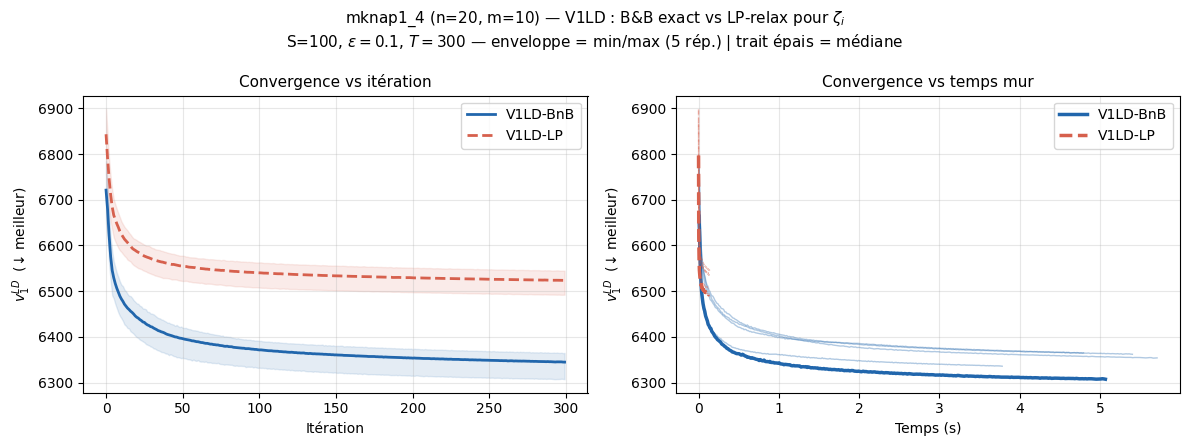

Sauvegarde : convergence_bnb_vs_lp.png


In [3]:
inst_lbl = list(INSTANCES.keys())[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# ── subplot gauche : convergence vs itération ─────────────────────────────────
ax = axes[0]
for name, _, color, ls in VARIANTS:
    convs = [np.array(r['convergence']) for r in results[inst_lbl][name]]
    L = min(len(c) for c in convs)
    mat = np.stack([c[:L] for c in convs])
    mu  = mat.mean(0)
    ax.plot(mu, color=color, ls=ls, lw=2, label=name)
    ax.fill_between(np.arange(L), mat.min(0), mat.max(0),
                    color=color, alpha=0.12)
ax.set_title('Convergence vs itération', fontsize=11)
ax.set_xlabel('Itération')
ax.set_ylabel('$v_1^{LD}$  (↓ meilleur)')
ax.legend()
ax.grid(True, alpha=0.3)

# ── subplot droit : convergence vs temps mur ──────────────────────────────────
ax = axes[1]
for name, _, color, ls in VARIANTS:
    for r in results[inst_lbl][name]:
        conv  = np.array(r['convergence'])
        times = np.array(r['times_s'])
        t_vec = times if len(times) == len(conv) \
                      else np.linspace(0, r['solve_time_s'], len(conv))
        ax.plot(t_vec, conv, color=color, ls=ls, lw=1.0, alpha=0.35)
    med = sorted(results[inst_lbl][name],
                 key=lambda r: r['solve_time_s'])[N_REPS // 2]
    conv  = np.array(med['convergence'])
    times = np.array(med['times_s'])
    t_vec = times if len(times) == len(conv) \
                  else np.linspace(0, med['solve_time_s'], len(conv))
    ax.plot(t_vec, conv, color=color, ls=ls, lw=2.5, label=name)
ax.set_title('Convergence vs temps mur', fontsize=11)
ax.set_xlabel('Temps (s)')
ax.set_ylabel('$v_1^{LD}$  (↓ meilleur)')
ax.legend()
ax.grid(True, alpha=0.3)

fig.suptitle(
    f'{inst_lbl} — V1LD : B&B exact vs LP-relax pour $\\zeta_i$\n'
    f'S=100, $\\varepsilon={EPSILON}$, $T={T}$ — enveloppe = min/max (5 rép.) | trait épais = médiane',
    fontsize=11)
plt.tight_layout()
plt.savefig('convergence_bnb_vs_lp.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegarde : convergence_bnb_vs_lp.png')

In [4]:
print(f'{'Instance':<28}  {'Variante':<12}  {'Borne moy.':>12}  {'t moy.(s)':>10}  {'ms/iter':>8}  {'Speedup':>8}')
print('-' * 82)

for inst_lbl in inst_labels:
    ref_time = None
    for name, *_ in VARIANTS:
        data   = results[inst_lbl][name]
        bounds = [r['v1LD_star']      for r in data]
        times  = [r['solve_time_s']   for r in data]
        iters  = [r['iterations_run'] for r in data]
        t_mean = np.mean(times)
        ms_it  = np.mean([t/it*1000 for t,it in zip(times,iters)])
        if ref_time is None:
            ref_time = t_mean
            speedup_str = '1.0×  (ref)'
        else:
            speedup_str = f'{ref_time/t_mean:.1f}× plus rapide'
        tag = inst_lbl.replace('\n', ' ')
        print(f'{tag:<28}  {name:<12}  {np.mean(bounds):>12.2f}  {t_mean:>10.2f}  {ms_it:>8.2f}  {speedup_str}')

SyntaxError: f-string: expecting '}' (2650427789.py, line 1)